# H3 · La pérdida del brazo B es sistemática y se concentra en retornos y flujos paralelos

**Hipótesis.** Las aristas que Stage 2 pierde con la respuesta correcta delante no son ruido
de muestreo ni un artefacto del evaluador: son siempre las mismas clases de arista.

**Veredicto: se sostiene.** De las 361 aristas de la referencia, 53 las pierden las tres
corridas (Flash, su réplica y Claude) en los mismos videos. 27 son de ida y vuelta, 17 son
pares repetidos y 8 tocan un servicio con varios nodos. De las 57 aristas simples se pierde una.

**Lo que no prueba.** Que la causa sea el prompt. Es compatible con sus reglas de fusión y
ruteo, pero un modelo también puede deduplicar por su cuenta.

## Archivos usados, cómo se generaron y dónde quedaron

No hubo llamadas nuevas: este análisis relee las salidas del brazo B.

| qué | dónde |
|---|---|
| Salidas de Flash, brazo B | `reports/ablation/2026-08-28_0315_…_oracle-oracle_gt/run.json` |
| Salidas de Flash, réplica 2 | `reports/ablation/2026-08-28_2211_…_oracle-oracle_gt_rep2/run.json` |
| Salidas de Claude, brazo B | `reports/claude_oracle_gt/run.json` |
| Referencia | `data/cloudscape_gt/<vid>.graphml` |
| Cómo se clasifica cada arista | `hipotesis/comun.py`, función `tipo_arista` |

Cada arista de la referencia cae en una sola clase, en este orden: auto-arista, par repetido
(el mismo par origen→destino aparece más de una vez), servicio con varios nodos, ida y vuelta
(existe la arista inversa), con actor `User*`, simple.
Figuras de este notebook: `hipotesis/figuras/H3_*.png`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import comun as c

c.estilo()
from collections import Counter

TRES = ["B_flash", "B_flash_rep2", "B_claude"]
videos = list(c.filas("B_flash"))
perdidas = {k: {v: c.gt(v)[1] - c.gen(c.filas(k)[v]) for v in videos} for k in TRES}
comunes = {v: perdidas[TRES[0]][v] & perdidas[TRES[1]][v] & perdidas[TRES[2]][v] for v in videos}

total, perdidas_tipo = Counter(), Counter()
for v in videos:
    for (a, b), n in c.gt(v)[1].items():
        total[c.tipo_arista(v, a, b)] += n
    for (a, b), n in comunes[v].items():
        perdidas_tipo[c.tipo_arista(v, a, b)] += n

n, distintas = c.verificar(TRES)
print(f"Control: el F1 recalculado coincide con el del evaluador en {n - distintas} de {n} filas.")
print(f"Aristas en la referencia: {sum(total.values())} · perdidas por las tres corridas: {sum(perdidas_tipo.values())}")
c.Tabla(["clase de arista", "en la referencia", "perdidas por las tres", "%"],
        [[t, total[t], perdidas_tipo[t], f"{100 * perdidas_tipo[t] / total[t]:.0f} %"] for t in c.TIPOS])

Control: el F1 recalculado coincide con el del evaluador en 90 de 90 filas.
Aristas en la referencia: 361 · perdidas por las tres corridas: 53


clase de arista,en la referencia,perdidas por las tres,%
ida y vuelta,108,27,25 %
par repetido,78,17,22 %
servicio con varios nodos,92,8,9 %
con actor User*,15,0,0 %
auto-arista,11,0,0 %
simple,57,1,2 %


## 1 · Qué clase de arista se pierde

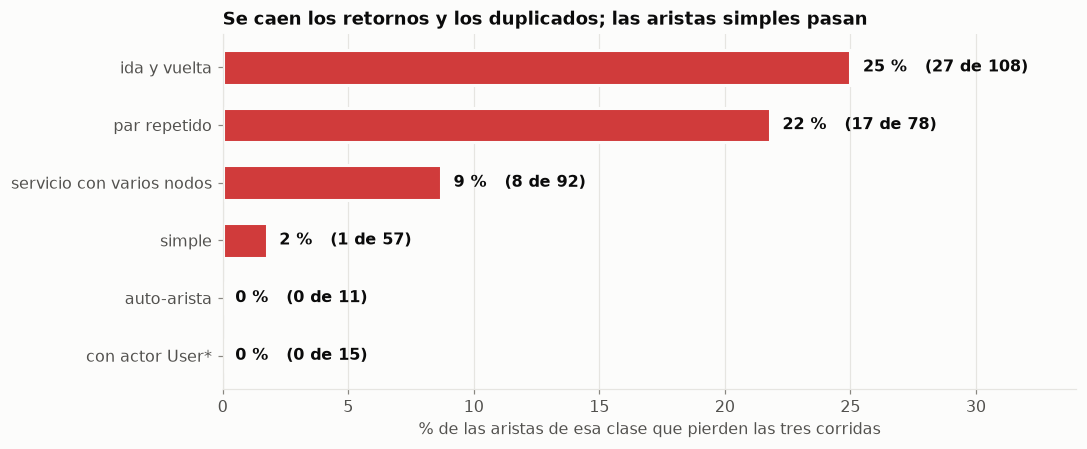

In [2]:
orden = sorted(c.TIPOS, key=lambda t: perdidas_tipo[t] / total[t])
tasa = [100 * perdidas_tipo[t] / total[t] for t in orden]
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(orden, tasa, height=0.6, color=c.FALTA, edgecolor=c.FONDO, linewidth=2)
for y, t in enumerate(orden):
    ax.text(tasa[y] + 0.5, y, f"{tasa[y]:.0f} %   ({perdidas_tipo[t]} de {total[t]})", va="center", fontweight="bold")
ax.set_xlim(0, 34)
ax.set_xlabel("% de las aristas de esa clase que pierden las tres corridas")
ax.set_title("Se caen los retornos y los duplicados; las aristas simples pasan")
ax.grid(axis="y", visible=False)
fig.tight_layout()
c.guardar(fig, "H3_tasa_por_clase")

## 2 · El patrón se repite en cada corrida y en cada condición

Lo mismo, corrida por corrida, incluidas las de Pro y las que no reciben pizarra ni transcript (H4).

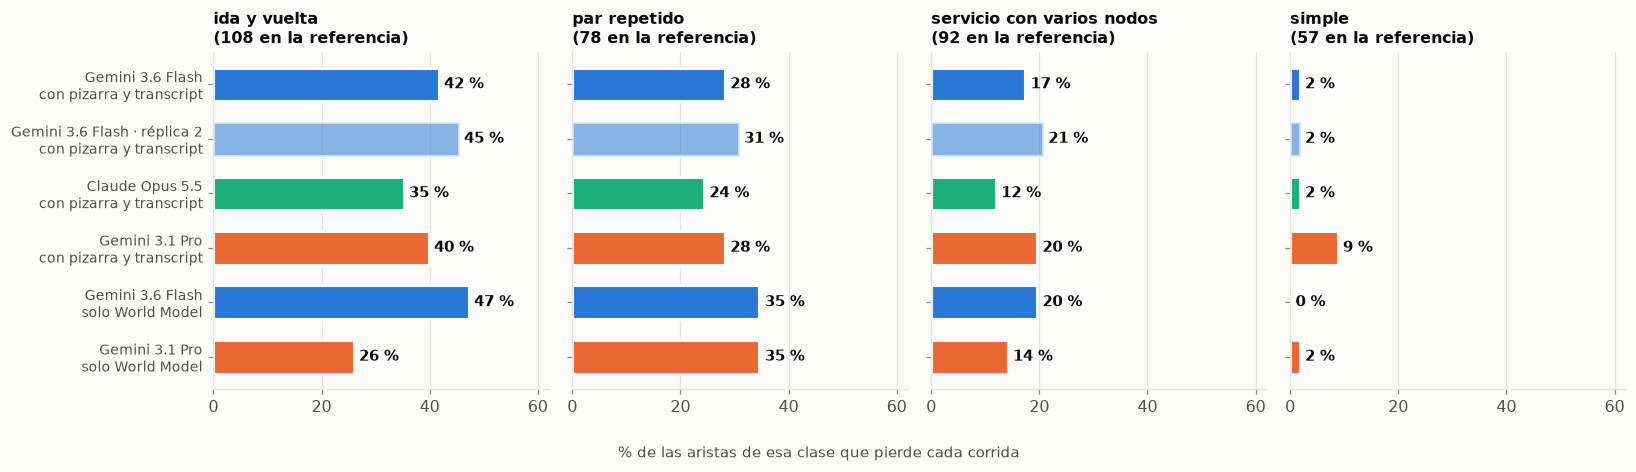

In [3]:
corridas = [k for k in ["B_flash", "B_flash_rep2", "B_claude", "B_pro", "Bwm_flash", "Bwm_pro"] if c.existe(k)]
nombres = {"B": "con pizarra y transcript", "Bwm": "solo World Model"}
clases = ["ida y vuelta", "par repetido", "servicio con varios nodos", "simple"]
fig, ax = plt.subplots(1, len(clases), figsize=(15, 4.3), sharey=True)
for a, clase in zip(ax, clases):
    for y, k in enumerate(reversed(corridas)):
        perd = sum(n for v in videos for (s, t), n in (c.gt(v)[1] - c.gen(c.filas(k)[v])).items()
                   if c.tipo_arista(v, s, t) == clase)
        pct = 100 * perd / total[clase]
        a.barh(y, pct, height=0.62, color=c.COLOR[c.modelo(k)], alpha=0.55 if k.endswith("rep2") else 1,
               edgecolor=c.FONDO, linewidth=2)
        a.text(pct + 1, y, f"{pct:.0f} %", va="center", fontweight="bold", fontsize=9.5)
    a.set_title(f"{clase}\n({total[clase]} en la referencia)", fontsize=10.5)
    a.set_xlim(0, 62)
    a.grid(axis="y", visible=False)
ax[0].set_yticks(range(len(corridas)), [f"{c.etiqueta(k)}\n{nombres[k.split('_')[0]]}" for k in reversed(corridas)], fontsize=9)
fig.supxlabel("% de las aristas de esa clase que pierde cada corrida", fontsize=10, color=c.TINTA2)
fig.tight_layout()
c.guardar(fig, "H3_por_corrida")

## 3 · ¿Son las mismas aristas?

Coincidencia entre corridas: aristas perdidas por las dos, sobre aristas perdidas por alguna de las dos.

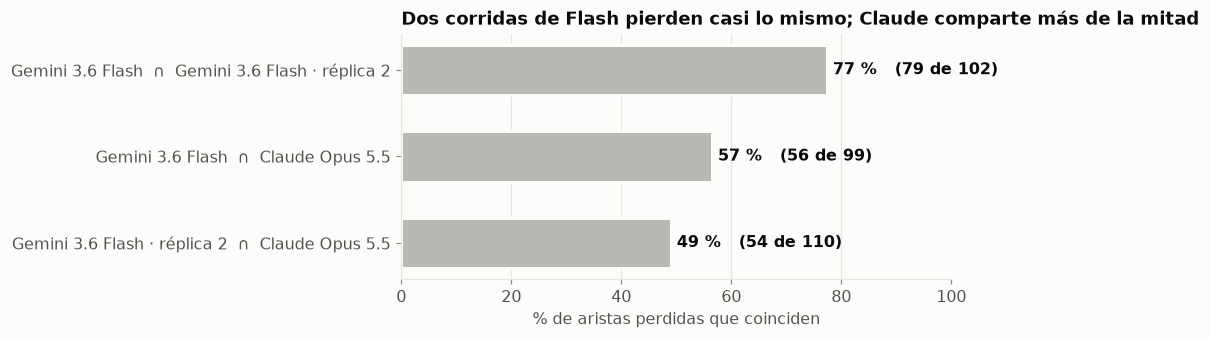

In [4]:
def coincidencia(a, b):
    inter = sum(sum((perdidas[a][v] & perdidas[b][v]).values()) for v in videos)
    union = sum(sum((perdidas[a][v] | perdidas[b][v]).values()) for v in videos)
    return inter, union

pares = [("B_flash", "B_flash_rep2"), ("B_flash", "B_claude"), ("B_flash_rep2", "B_claude")]
fig, ax = plt.subplots(figsize=(9, 3.2))
for y, (a, b) in enumerate(reversed(pares)):
    i, u = coincidencia(a, b)
    ax.barh(y, 100 * i / u, height=0.58, color=c.NEUTRO, edgecolor=c.FONDO, linewidth=2)
    ax.text(100 * i / u + 1, y, f"{100 * i / u:.0f} %   ({i} de {u})", va="center", fontweight="bold")
ax.set_yticks(range(len(pares)), [f"{c.etiqueta(a)}  ∩  {c.etiqueta(b)}" for a, b in reversed(pares)])
ax.set_xlim(0, 100)
ax.set_xlabel("% de aristas perdidas que coinciden")
ax.set_title("Dos corridas de Flash pierden casi lo mismo; Claude comparte más de la mitad")
ax.grid(axis="y", visible=False)
fig.tight_layout()
c.guardar(fig, "H3_coincidencia")

## 4 · El video donde más aristas pierden las tres

Las flechas rojas punteadas están en la referencia (y en la entrada de Stage 2) y no en la salida.

ww5fiygF6eg · aristas que pierden las tres corridas:
   ThirdParty → Lambda   [par repetido]
   S3 → Lambda   [par repetido]
   S3 → StorageGateway   [ida y vuelta]
   StorageGateway → ThirdParty   [servicio con varios nodos]
   Lambda → ThirdParty   [par repetido]
   Lambda → StepFunctions   [par repetido] ×2
   Lambda → S3   [par repetido]


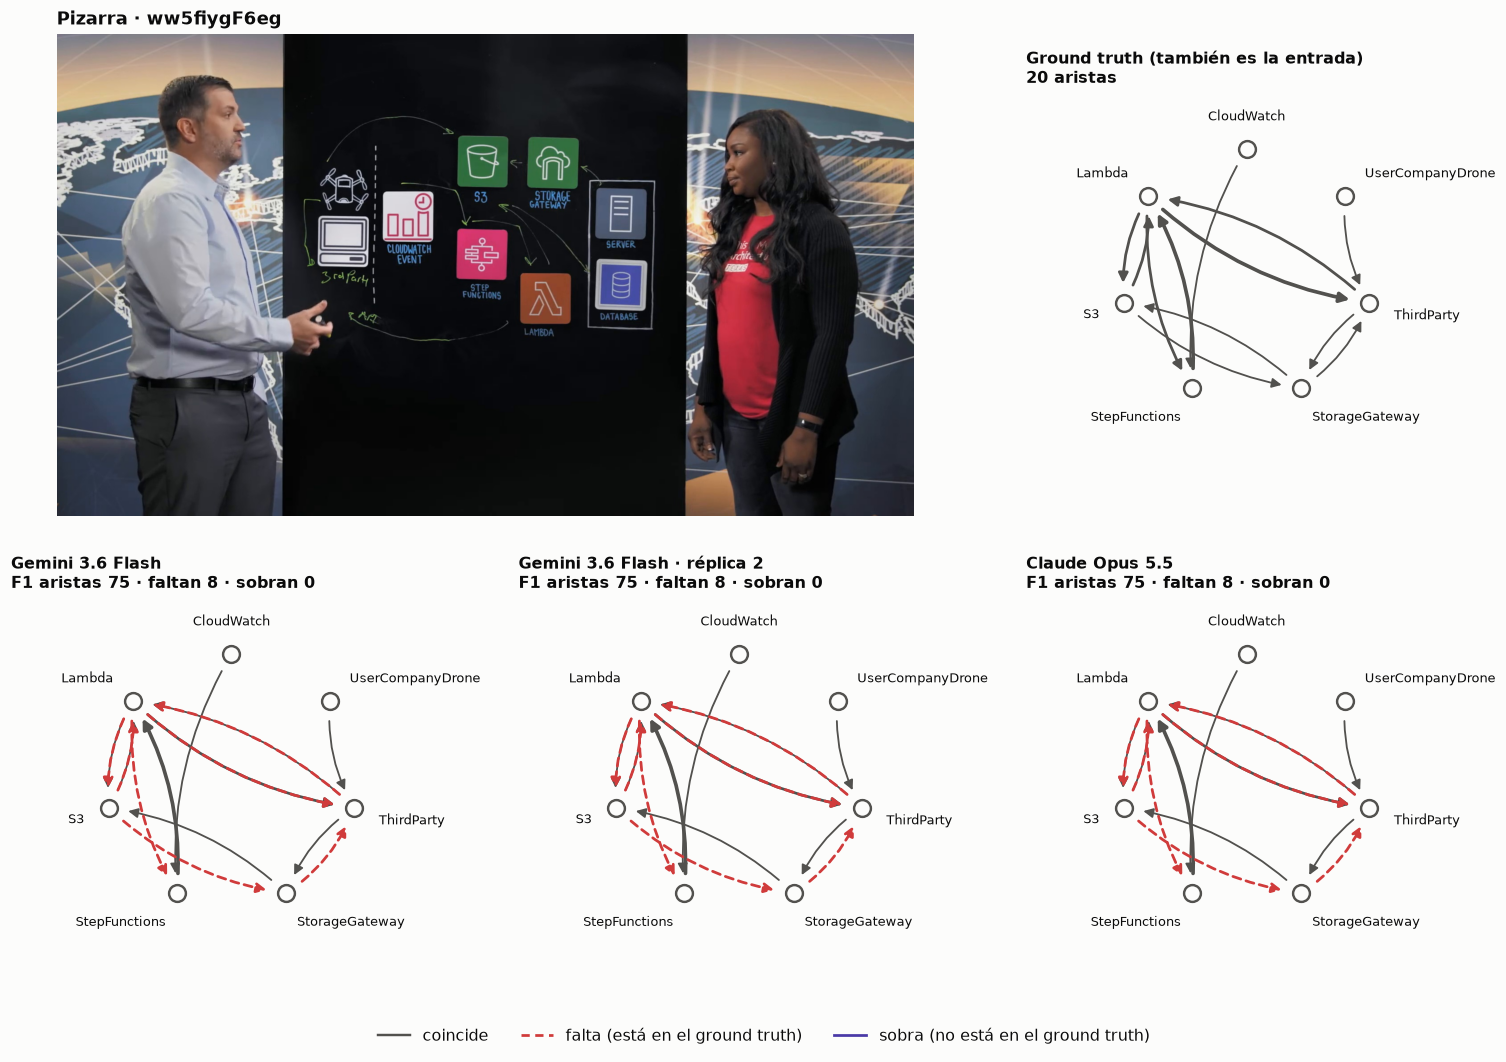

In [5]:
vid = max(videos, key=lambda v: sum(comunes[v].values()))
print(vid, "· aristas que pierden las tres corridas:")
for (a, b), n in comunes[vid].items():
    print(f"   {a} → {b}   [{c.tipo_arista(vid, a, b)}]" + (f" ×{n}" if n > 1 else ""))
fig = plt.figure(figsize=(14, 9.5))
gs = fig.add_gridspec(2, 3)
c.pizarra(fig.add_subplot(gs[0, :2]), vid)
c.grafo(fig.add_subplot(gs[0, 2]), vid, titulo="Ground truth (también es la entrada)")
for i, k in enumerate(TRES):
    c.grafo(fig.add_subplot(gs[1, i]), vid, c.filas(k)[vid], c.etiqueta(k))
c.leyenda_grafo(fig)
fig.tight_layout()
c.guardar(fig, "H3_ejemplo")

## Qué aporta al paper

La pérdida de Stage 2 tiene forma: retornos y flujos paralelos. Descarta el evaluador y la
conversión del ground truth como causa (el F1 se recalcula igual desde las salidas crudas y el
World Model oráculo tiene techo de copia 100/100). Queda por separar si lo causa el prompt o el
modelo: es el experimento del prompt mínimo, que todavía no se corrió.